# 02 - Arrays and properties

The numbers of a package are in its HDF5 file: geometry, and the properties hung on a
representation. This notebook weighs an array before reading it, reads only a slab of it,
then reads the properties of a 3D grid and of a well, with their units. It runs on **Lutetia**, a synthetic model (CC BY 4.0) built on boreholes of the BRGM Banque du sous-sol (Licence Ouverte 2.0), modified for the example: [geosiris-technologies/energyml-lutetia](https://github.com/geosiris-technologies/energyml-lutetia). The first run downloads it (27 MB) at the commit this repository pins; see [`_lutetia.py`](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/_lutetia.py).

```
pip install energyml-rust matplotlib pandas
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energyml.rust.epc import Epc
from energyml.rust.resqml import geometry_of, properties_of

from _lutetia import lutetia

root = lutetia()
pkg = Epc.open(str(root / "package" / "Lutetia.epc"))

## Weigh first, read what you need

`array_shape` reads the dataset's header only. `read_array_part` reads a slab, `start` and
`count` per dimension, as ETP's subarrays do: on a large grid, one layer instead of all.

In [2]:
porosity = pkg.find("ContinuousProperty", "Ypresian-Chalk grid - porosity")[0]
array = pkg.arrays(porosity.uri)[0]
print(array.path_in_file, pkg.array_shape(array))

grid = next(g for g in pkg.find("IjkGridRepresentation") if g.title == "Ypresian-Chalk grid")
ni, nj, nk = geometry_of(pkg, grid.uri)["patches"][0]["dimensions"]
layer, shape = pkg.read_array_part(array, [ni * nj * 4], [ni * nj])
whole, _ = pkg.read_array(array)
print(f"layer K=4: {shape} values, the same as in the whole array: {np.array_equal(layer, whole[4 * ni * nj:5 * ni * nj])}")

/resqml22/bc5c4161-2f2a-50b7-8a97-1bb6db21265f/values {'dimensions': [65520], 'element_type': 'double'}
layer K=4: [6552] values, the same as in the whole array: True


## The properties of a grid

`properties_of` finds every property hung on a representation, with its kind, unit and
element (`cells`, `nodes`...), and returns the values as numpy arrays. Its second answer lists
what it could not read: a property dropped in silence would be a colour you never learn is
missing.

In [3]:
values, problems = properties_of(pkg, grid.uri)
print("problems:", problems)
table = pd.DataFrame(
    {"name": p["name"], "kind": p["kind"], "uom": p["uom"], "on": p["scope"],
     "min": np.nanmin(p["values"]), "max": np.nanmax(p["values"])}
    for p in values
)
table

problems: ['`Ypresian-Chalk grid - temperature - Lutetia - doublet operation, year by year` has 720720 value(s) for 65520 cell(s) × 1 component(s); it was not attached, because lining it up would put values on elements they do not belong to', '`Ypresian-Chalk grid - pressure - Lutetia - doublet operation, year by year` has 720720 value(s) for 65520 cell(s) × 1 component(s); it was not attached, because lining it up would put values on elements they do not belong to']


,name,kind,uom,on,min,max
0,Ypresian-Chalk grid - pressure,pressure,bar,cells,1.800983,15.985566
1,Ypresian-Chalk grid - permeability (kx),absolute permeability,mD,cells,5.000000,200.000000
2,Ypresian-Chalk grid - permeability (kz),absolute permeability,mD,cells,1.000000,50.000000
3,Ypresian-Chalk grid - net gross thickness ratio,net gross thickness ratio,Euc,cells,0.900000,1.000000
4,Ypresian-Chalk grid - permeability (ky),absolute permeability,mD,cells,5.000000,200.000000
5,Ypresian-Chalk grid - porosity,porosity,Euc,cells,0.300000,0.350000
6,Ypresian-Chalk grid - temperature,temperature,degC,cells,12.639933,17.163979


The two problems are worth reading. Two properties hold a value per cell **and per
year**, a time series, and `properties_of` lines values up with cells one to one: rather than
put a year's value on the wrong cell, it leaves them out and says so.

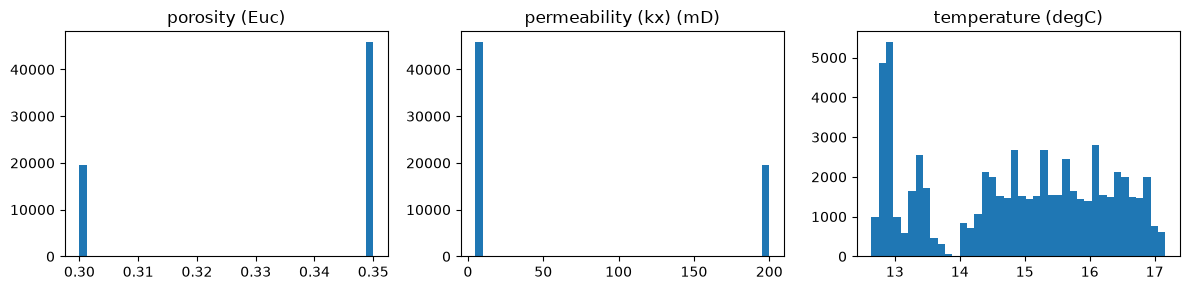

In [4]:
by_name = {p["name"].split(" - ", 1)[1]: p for p in values}
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, name in zip(axes, ["porosity", "permeability (kx)", "temperature"]):
    p = by_name[name]
    data = p["values"][np.isfinite(p["values"])]
    ax.hist(data, bins=40)
    ax.set_title(f"{name} ({p['uom']})")
plt.tight_layout()
plt.show()

Placed on the geometry of the grid, a property becomes a map: the centre of every cell of
layer K=4, coloured by temperature (the porosity of this synthetic model is constant within a layer).

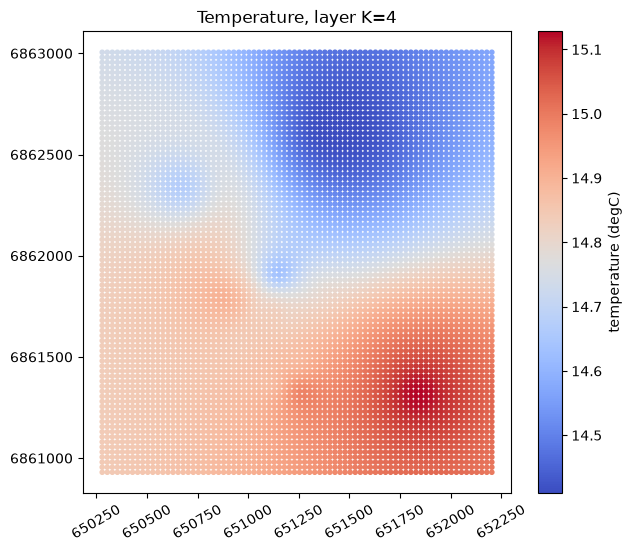

In [5]:
patch = geometry_of(pkg, grid.uri)["patches"][0]
corners = patch["cells"].reshape(-1, 8)
centres = patch["points"].reshape(-1, 3)[corners].mean(axis=1)
# `cell_index` is empty when every cell is there in order (see notebook 01).
number = patch["cell_index"] if len(patch["cell_index"]) else np.arange(len(corners))
in_layer = number // (ni * nj) == 4
fig, ax = plt.subplots(figsize=(7, 6))
shown = ax.scatter(centres[in_layer, 0], centres[in_layer, 1],
                   c=by_name["temperature"]["values"][number[in_layer]], s=9, cmap="coolwarm")
fig.colorbar(shown, ax=ax, label="temperature (degC)")
ax.set_title("Temperature, layer K=4")
ax.ticklabel_format(useOffset=False, style="plain")
ax.tick_params(axis="x", labelrotation=30)
ax.set_aspect("equal")
plt.show()

## A well, through time

The well GTH-1 carries a pressure profile per year, each a property on the nodes of its
frame. The frame's own array gives the measured depth of each node.

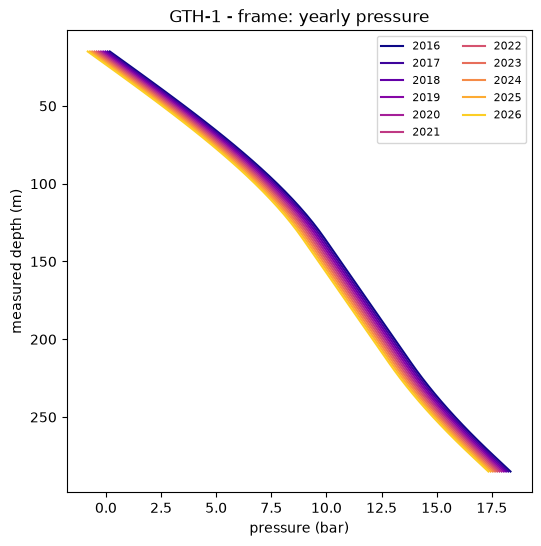

In [6]:
frame = pkg.find("WellboreFrameRepresentation", "GTH-1 - frame")[0]
md, _ = pkg.read_array(pkg.arrays(frame.uri)[0])
logs, problems = properties_of(pkg, frame.uri)
yearly = sorted((p for p in logs if "yearly" in p["name"]), key=lambda p: p["name"])

fig, ax = plt.subplots(figsize=(6, 6))
for p, colour in zip(yearly, plt.cm.plasma(np.linspace(0, 0.9, len(yearly)))):
    ax.plot(p["values"], md, color=colour, label=p["name"].rsplit(" - ", 1)[1][:4])
ax.invert_yaxis()
ax.set_xlabel(f"pressure ({yearly[0]['uom']})")
ax.set_ylabel("measured depth (m)")
ax.set_title(f"{frame.title}: yearly pressure")
ax.legend(ncol=2, fontsize=8)
plt.show()

The nodes above the first measurement carry no value: they come back as `NaN`, and are
not drawn, rather than as a zero that would look like a measurement.

## The other notebooks

- [00 - What is in this package?](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/00-what-is-in-a-package.ipynb)
- [01 - Geometry, from 2D grids to 3D cells](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/01-geometry-in-3d.ipynb)
- [03 - Is this package valid?](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/03-is-this-package-valid.ipynb)
- [04 - A package from nothing](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/04-a-package-from-nothing.ipynb)
- [05 - Editing a package](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/05-editing-a-package.ipynb)
- [06 - Exporting to other tools](https://github.com/geosiris-technologies/energyml-rust/blob/main/examples/notebooks/06-exporting.ipynb)